<a href="https://colab.research.google.com/github/IvanRUDN/IST2026_autumn/blob/main/Lab3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторная работа №3. Оптимизация в машинном обучении

В работе реализованы оракулы функций, градиентный спуск, метод Ньютона и логистическая регрессия с L2-регуляризацией.

In [16]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.sparse
import optimization
import oracles
from plot_trajectory_2d import plot_levels, plot_trajectory


##  Проверка квадратичного оракула

In [17]:
A = np.array([[4.0, 1.0], [1.0, 2.0]])
b = np.array([1.0, 1.0])
oracle = oracles.QuadraticOracle(A, b)
x = np.array([0.0, 0.0])
print('Значение функции:', oracle.func(x))
print('Градиент:', oracle.grad(x))
print('Матрица Гессе:')
print(oracle.hess(x))

Значение функции: 0.0
Градиент: [-1. -1.]
Матрица Гессе:
[[4. 1.]
 [1. 2.]]


##  Численная оценка градиента и матрицы Гессе

In [18]:
def test_func(x):
    return x[0] ** 3 + x[1] ** 2

point = np.array([2.0, 3.0])
print('Численный градиент:', oracles.grad_finite_diff(test_func, point))
print('Численная матрица Гессе:')
print(oracles.hess_finite_diff(test_func, point))

Численный градиент: [11.99999993  5.99999979]
Численная матрица Гессе:
[[12.00003652  0.        ]
 [ 0.          2.00003569]]


##  Градиентный спуск

Результат: [0.1428571  0.42857158]
Статус: success
Значение функции: -0.28571428571426516


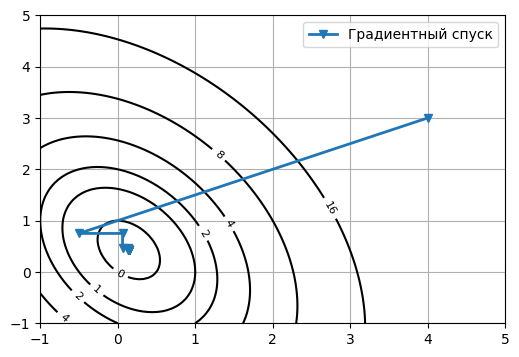

In [25]:
x0 = np.array([4.0, 3.0])
x_gd, message_gd, history_gd = optimization.gradient_descent(
    oracle, x0, tolerance=1e-6,
    line_search_options={'method': 'Wolfe'}, trace=True
)
print('Результат:', x_gd)
print('Статус:', message_gd)
print('Значение функции:', oracle.func(x_gd))
plt.figure(figsize=(6, 4))
plot_levels(oracle.func, xrange=[-1, 5], yrange=[-1, 5], levels=[-1, 0, 1, 2, 4, 8, 16])
plot_trajectory(oracle.func, history_gd['x'], label='Градиентный спуск')
plt.legend(); plt.show()

In [23]:
print("Градиент:", oracle.grad(x_gd))
print("Норма градиента:", np.linalg.norm(oracle.grad(x_gd)))
print("Значение функции:", oracle.func(x_gd))

Градиент: [0.00000000e+00 2.68220901e-07]
Норма градиента: 2.682209014892578e-07
Значение функции: -0.28571428571426516


##  Метод Ньютона

Результат: [0.14285714 0.42857143]
Статус: success
Значение функции: -0.2857142857142857


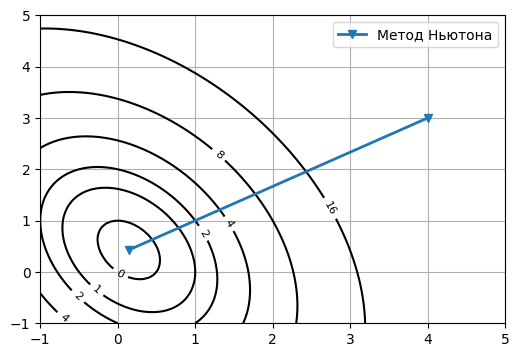

In [26]:
x_newton, message_newton, history_newton = optimization.newton(
    oracle, x0, tolerance=1e-7,
    line_search_options={'method': 'Constant', 'c': 1.0}, trace=True
)
print('Результат:', x_newton)
print('Статус:', message_newton)
print('Значение функции:', oracle.func(x_newton))
plt.figure(figsize=(6, 4))
plot_levels(oracle.func, xrange=[-1, 5], yrange=[-1, 5], levels=[-1, 0, 1, 2, 4, 8, 16])
plot_trajectory(oracle.func, history_newton['x'], label='Метод Ньютона')
plt.legend(); plt.show()

##  Сравнение методов

Градиентный спуск: итераций = 16
Метод Ньютона: итераций = 1


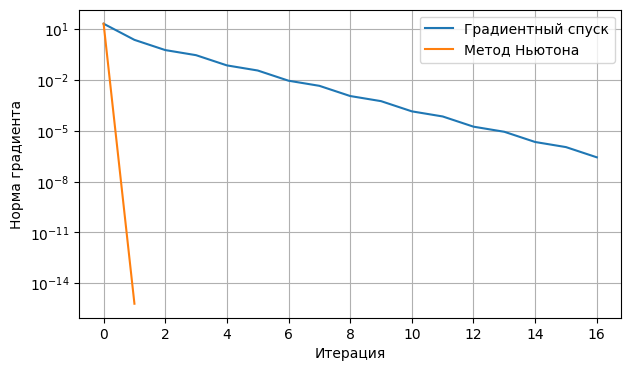

In [21]:
print('Градиентный спуск: итераций =', len(history_gd['func']) - 1)
print('Метод Ньютона: итераций =', len(history_newton['func']) - 1)
plt.figure(figsize=(7, 4))
plt.semilogy(history_gd['grad_norm'], label='Градиентный спуск')
plt.semilogy(history_newton['grad_norm'], label='Метод Ньютона')
plt.xlabel('Итерация'); plt.ylabel('Норма градиента'); plt.grid(); plt.legend(); plt.show()

## Логистическая регрессия с L2-регуляризацией



In [30]:
import numpy as np
from pathlib import Path
from sklearn.datasets import load_svmlight_file

data_dir = Path('data')
for filename in ['w8a.txt', 'gisette_scale', 'real-sim']:
    path = data_dir / filename
    if path.exists():
        A_data, b_data = load_svmlight_file(str(path))
        b_data = np.where(b_data > 0, 1, -1)
        logreg = oracles.LogRegL2Oracle(A_data, b_data, regcoef=1e-3)
        start = np.zeros(A_data.shape[1])
        result, status, hist = optimization.gradient_descent(
            logreg, start, tolerance=1e-5, max_iter=1000,
            line_search_options={'method': 'Armijo'}, trace=True
        )
        print(filename, 'status:', status, 'iterations:', len(hist['func']) - 1,
              'final loss:', logreg.func(result))


w8a.txt status: iterations_exceeded iterations: 1000 final loss: 0.18379677069171532
gisette_scale status: iterations_exceeded iterations: 1000 final loss: 0.10751323319070707
real-sim status: iterations_exceeded iterations: 1000 final loss: 0.4951034135404632
